# Eksperymenty: ofiara i drapieżnik

Każda próba startuje z 30 ofiarami i 30 drapieżnikami i trwa 150 kroków. W każdym scenariuszu używamy 10 ziaren (0–9). Wymarcie oznacza brak osobników danego gatunku po ostatnim kroku.

In [5]:
%matplotlib inline

from src.prey_predator_sim.simulation import BASE_HUNT, BASE_REPRODUCE, SEEDS, STEPS, report, simulate
from src.prey_predator_sim.species import Prey, Predator

reproduce_values = (0.25, 0.30, 0.35)
hunt_values = (0.20, 0.35, 0.70)
print(f"Konfiguracja: {STEPS} kroków, {len(SEEDS)} ziaren na scenariusz.")

Konfiguracja: 150 kroków, 10 ziaren na scenariusz.



Baza: p_reproduce=0.4, p_hunt=0.5 (10 prob, krok 150)
  Prey: wymarcie 90%, mean: 9.70, std: 30.67
  Predator: wymarcie 100%, mean: 0.00, std: 0.00


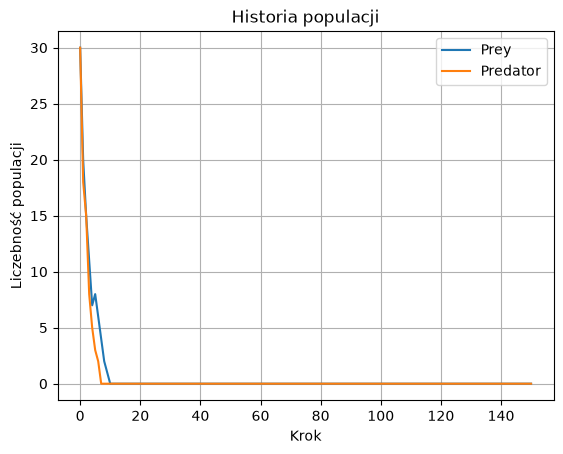

In [6]:
baseline = [simulate(seed, BASE_REPRODUCE, BASE_HUNT) for seed in SEEDS]
repeated = simulate(SEEDS[0], BASE_REPRODUCE, BASE_HUNT)
assert baseline[0].history[0] == {Prey: 30, Predator: 30}
assert len(baseline[0].history) == STEPS + 1
assert baseline[0].history == repeated.history and baseline[0].n == repeated.n
report(f"Baza: p_reproduce={BASE_REPRODUCE}, p_hunt={BASE_HUNT}", baseline)
baseline[0].plot_history()

Analiza wrażliwości: zmiana jednego parametru naraz.

Prey.default_p_reproduce=0.25 (10 prob, krok 150)
  Prey: wymarcie 100%, mean: 0.00, std: 0.00
  Predator: wymarcie 100%, mean: 0.00, std: 0.00


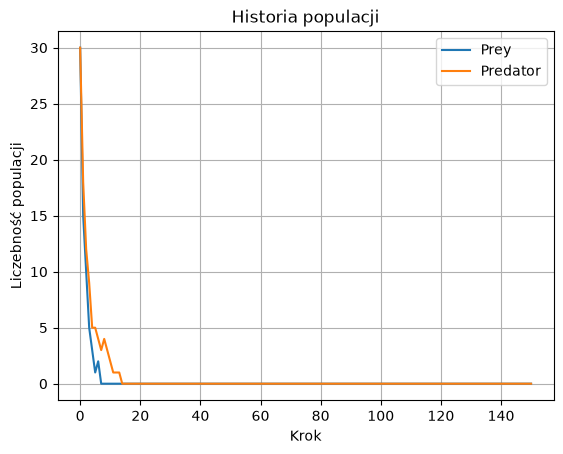


Prey.default_p_reproduce=0.30 (10 prob, krok 150)
  Prey: wymarcie 100%, mean: 0.00, std: 0.00
  Predator: wymarcie 100%, mean: 0.00, std: 0.00


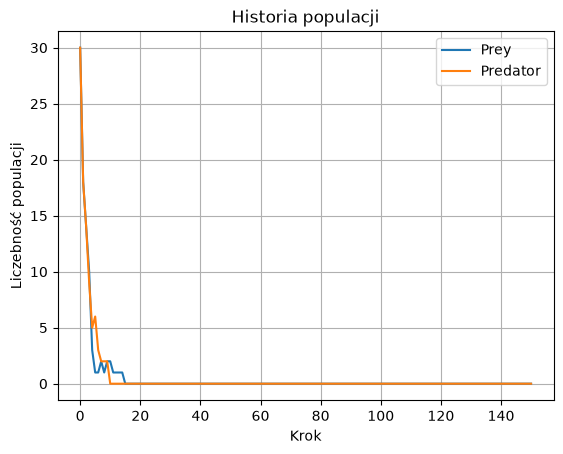


Prey.default_p_reproduce=0.35 (10 prob, krok 150)
  Prey: wymarcie 100%, mean: 0.00, std: 0.00
  Predator: wymarcie 100%, mean: 0.00, std: 0.00


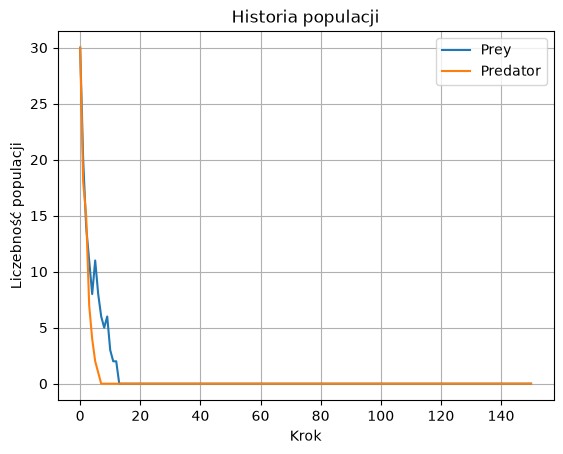


Prey.default_p_hunt=0.20 (10 prob, krok 150)
  Prey: wymarcie 60%, mean: 36.30, std: 75.85
  Predator: wymarcie 100%, mean: 0.00, std: 0.00


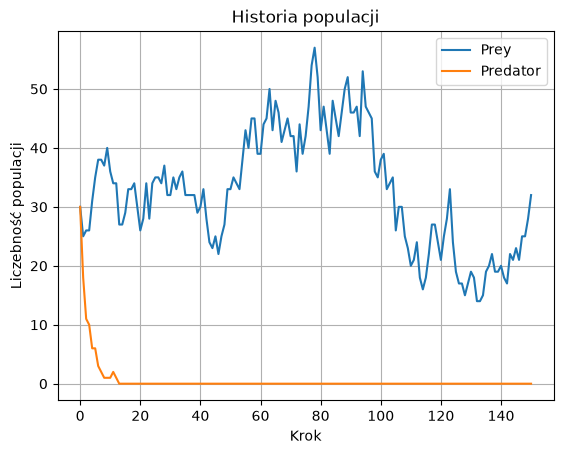


Prey.default_p_hunt=0.35 (10 prob, krok 150)
  Prey: wymarcie 80%, mean: 21.10, std: 65.68
  Predator: wymarcie 100%, mean: 0.00, std: 0.00


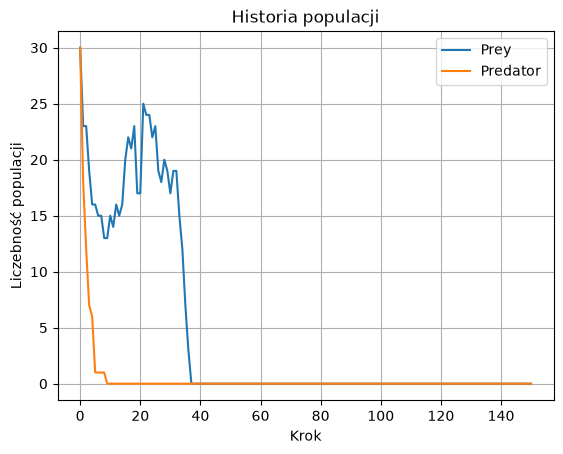


Prey.default_p_hunt=0.70 (10 prob, krok 150)
  Prey: wymarcie 80%, mean: 3.80, std: 11.33
  Predator: wymarcie 100%, mean: 0.00, std: 0.00


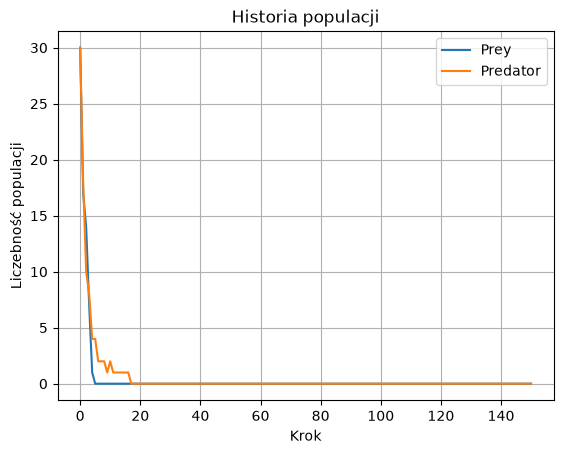

In [7]:
print("Analiza wrażliwości: zmiana jednego parametru naraz.")
for value in reproduce_values:
    label = f"Prey.default_p_reproduce={value:.2f}"
    runs = [simulate(seed, value, BASE_HUNT) for seed in SEEDS]
    report(label, runs)
    runs[0].plot_history()
for value in hunt_values:
    label = f"Prey.default_p_hunt={value:.2f}"
    runs = [simulate(seed, BASE_REPRODUCE, value) for seed in SEEDS]
    report(label, runs)
    runs[0].plot_history()

Histogram po 150 krokach, ziarno 9.
{'Prey': 97, 'Predator': 0}


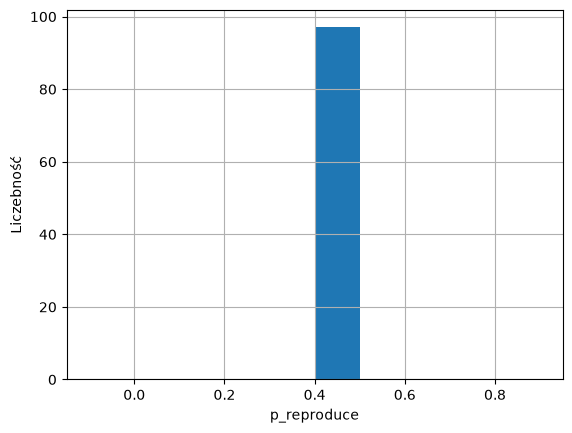

In [8]:
histogram_seed, histogram_run = next(
    ((seed, run) for seed, run in zip(SEEDS, baseline) if any(run.n.values())),
    (SEEDS[0], baseline[0]),
)
print(f"Histogram po {STEPS} krokach, ziarno {histogram_seed}.")
print({species.__name__: count for species, count in histogram_run.n.items()})
histogram_run.plot_histogram("p_reproduce")

## Wnioski z symulacji

Dwa uruchomienia scenariusza bazowego z ziarnem 0 dały identyczną historię i ten sam stan końcowy. Drapieżniki wymarły we wszystkich przeprowadzonych próbach. W badanych wariantach `p_hunt` im wyższa była skuteczność polowania, tym niższa była średnia końcowa liczebność ofiar. Wniosek dotyczy testowanych ustawień i 10 prób na scenariusz.

## Histogram i ograniczenia modelu

Histogram pokazuje `p_reproduce` osobników pozostałych po 150 krokach w pierwszej niepustej próbie bazowej (ziarno 9). Zostało w niej 97 ofiar i żadnego drapieżnika. Wszystkie ofiary miały `p_reproduce = 0.4`, dlatego na histogramie widać jeden słupek. Ofiary zaczynają z tym samym prawdopodobieństwem rozrodu, a potomstwo dziedziczy je bez zmian.

Model nie uwzględnia mutacji, ograniczonej dostępności zasobów ani rozmieszczenia osobników w przestrzeni. Wyniki opisują więc zachowanie tego uproszczonego modelu, a nie rzeczywistych populacji.